In [10]:
import csv
import json
from datetime import datetime

# Constante de limite para transações suspeitas
LIMITE_SUSPEITO = 10000.00

def formatar_moeda(valor):
    """Formata float para o padrão de moeda brasileiro (R$)."""
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

def validar_transacao(linha):
    """Valida uma única linha e retorna o registro limpo ou None se for inválida."""
    # Validação de campos vazios
    if not linha.get('id') or not linha.get('id').isdigit():
        return None
    if not linha.get('cliente id'):
        return None
    if linha.get('tipo') not in ['credito', 'debito']:
        return None

    # Try/Except 1: Conversão do valor para float
    try:
        valor = float(linha.get('valor'))
        if valor <= 0:
            return None
    except ValueError:
        return None

    # Try/Except 2: Conversão da data para datetime
    try:
        data_obj = datetime.strptime(linha.get('data'), "%Y-%m-%d")
    except ValueError:
        return None

    return {
        'id': int(linha.get('id')),
        'data': data_obj,
        'cliente_id': linha.get('cliente id'),
        'tipo': linha.get('tipo'),
        'valor': valor,
        'descricao': linha.get('descricao'),
        'categoria': linha.get('categoria')
    }

def ler_transacoes(caminho_arquivo):
    """Lê o CSV, valida os dados e retorna estatísticas e registros válidos."""
    transacoes_validas = []
    total_lidas = 0
    linhas_invalidas = 0

    # Try/Except 3: Abertura do arquivo CSV
    try:
        with open(caminho_arquivo, mode='r', encoding='utf-8') as arquivo:
            leitor = csv.DictReader(arquivo)
            for linha in leitor:
                total_lidas += 1
                transacao_limpa = validar_transacao(linha)

                if transacao_limpa:
                    transacoes_validas.append(transacao_limpa)
                else:
                    linhas_invalidas += 1

    except FileNotFoundError:
        print(f"Erro: O arquivo {caminho_arquivo} não foi encontrado.")
        return [], 0, 0

    print(f"Total de linhas lidas: {total_lidas}")
    print(f"Linhas válidas: {len(transacoes_validas)}")
    print(f"Linhas inválidas: {linhas_invalidas}\n")

    return transacoes_validas, len(transacoes_validas), linhas_invalidas

def gerar_relatorio(transacoes_validas):
    """Agrupa os dados por mês, calcula métricas e identifica transações suspeitas."""
    if not transacoes_validas:
        return {}, [], None, None

    resumo_mensal = {}
    transacoes_suspeitas = []
    datas = []

    for t in transacoes_validas:
        mes_ano = t['data'].strftime("%Y-%m")
        datas.append(t['data'])
        valor = t['valor']

        # Inicializa o mês se não existir
        if mes_ano not in resumo_mensal:
            resumo_mensal[mes_ano] = {
                "quantidade": 0, "total credito": 0.0, "total debito": 0.0,
                "saldo": 0.0, "maior_valor": valor, "menor_valor": valor
            }

        # Acumula as métricas
        resumo_mensal[mes_ano]["quantidade"] += 1
        if t['tipo'] == 'credito':
            resumo_mensal[mes_ano]["total credito"] += valor
        else:
            resumo_mensal[mes_ano]["total debito"] += valor

        # Atualiza maior e menor valor do mês
        if valor > resumo_mensal[mes_ano]["maior_valor"]:
            resumo_mensal[mes_ano]["maior_valor"] = valor
        if valor < resumo_mensal[mes_ano]["menor_valor"]:
            resumo_mensal[mes_ano]["menor_valor"] = valor

        # Verifica transação suspeita
        if valor > LIMITE_SUSPEITO:
            transacoes_suspeitas.append(t)

    # Finaliza cálculos mensais (saldo)
    for mes in resumo_mensal:
        resumo = resumo_mensal[mes]
        resumo["saldo"] = resumo["total credito"] - resumo["total debito"]
        resumo["media"] = (resumo["total credito"] + resumo["total debito"]) / resumo["quantidade"]

    data_mais_antiga = min(datas)
    data_mais_recente = max(datas)

    return resumo_mensal, transacoes_suspeitas, data_mais_antiga, data_mais_recente

def salvar_json(resumo_mensal, total_validas, total_invalidas, caminho_saida="relatorio.json"):
    """Salva o resultado formatado no arquivo JSON."""
    dados_json = {
        "gerado em": datetime.now().strftime("%Y-%m-%d"),
        "total transacoes validas": total_validas,
        "total transacoes invalidas": total_invalidas,
        "resumo mensal": resumo_mensal
    }

    with open(caminho_saida, 'w', encoding='utf-8') as f:
        json.dump(dados_json, f, ensure_ascii=False, indent=2)
    print(f"Relatório exportado com sucesso para {caminho_saida}\n")

def exibir_relatorio(resumo_mensal, transacoes_suspeitas, data_antiga, data_recente):
    """Formata e imprime os resultados no terminal."""
    print("===== RELATÓRIO MENSAL =====")
    if data_antiga and data_recente:
        dias = (data_recente - data_antiga).days
        print(f"Período analisado: {data_antiga.strftime('%Y-%m-%d')} a {data_recente.strftime('%Y-%m-%d')} ({dias} dias)\n")

    for mes, dados in sorted(resumo_mensal.items()):
        print(f"Mês: {mes}")
        print(f"Transações: {dados['quantidade']}")
        print(f"Total crédito: {formatar_moeda(dados['total credito'])}")
        print(f"Total débito:  {formatar_moeda(dados['total debito'])}")
        print(f"Saldo:         {formatar_moeda(dados['saldo'])}")
        print(f"Média:         {formatar_moeda(dados['media'])}")
        print(f"Maior valor:   {formatar_moeda(dados['maior_valor'])}")
        print(f"Menor valor:   {formatar_moeda(dados['menor_valor'])}")
        print("-" * 30)

    print("\n===== TRANSAÇÕES SUSPEITAS =====")
    if not transacoes_suspeitas:
        print("Nenhuma transação suspeita encontrada.")
    else:
        for t in transacoes_suspeitas:
            print(f"ID: {t['id']} | Cliente: {t['cliente_id']} | Data: {t['data'].strftime('%Y-%m-%d')} | Valor: {formatar_moeda(t['valor'])}")

# --- Célula de Execução Principal ---
if __name__ == "__main__":
    transacoes, qtd_validas, qtd_invalidas = ler_transacoes("/content/drive/MyDrive/Colab Notebooks/transacoes.csv")

    if transacoes:
        resumo, suspeitas, min_data, max_data = gerar_relatorio(transacoes)
        exibir_relatorio(resumo, suspeitas, min_data, max_data)
        salvar_json(resumo, qtd_validas, qtd_invalidas)

Total de linhas lidas: 20
Linhas válidas: 15
Linhas inválidas: 5

===== RELATÓRIO MENSAL =====
Período analisado: 2026-01-05 a 2026-03-25 (79 dias)

Mês: 2026-01
Transações: 4
Total crédito: R$ 5.500,00
Total débito:  R$ 630,50
Saldo:         R$ 4.869,50
Média:         R$ 1.532,62
Maior valor:   R$ 3.500,00
Menor valor:   R$ 180,50
------------------------------
Mês: 2026-02
Transações: 5
Total crédito: R$ 27.000,00
Total débito:  R$ 640,00
Saldo:         R$ 26.360,00
Média:         R$ 5.528,00
Maior valor:   R$ 15.000,00
Menor valor:   R$ 120,00
------------------------------
Mês: 2026-03
Transações: 6
Total crédito: R$ 4.000,00
Total débito:  R$ 1.249,90
Saldo:         R$ 2.750,10
Média:         R$ 874,98
Maior valor:   R$ 3.500,00
Menor valor:   R$ 50,00
------------------------------

===== TRANSAÇÕES SUSPEITAS =====
ID: 5 | Cliente: CLI003 | Data: 2026-02-14 | Valor: R$ 15.000,00
ID: 10 | Cliente: CLI005 | Data: 2026-02-20 | Valor: R$ 12.000,00
Relatório exportado com sucesso para

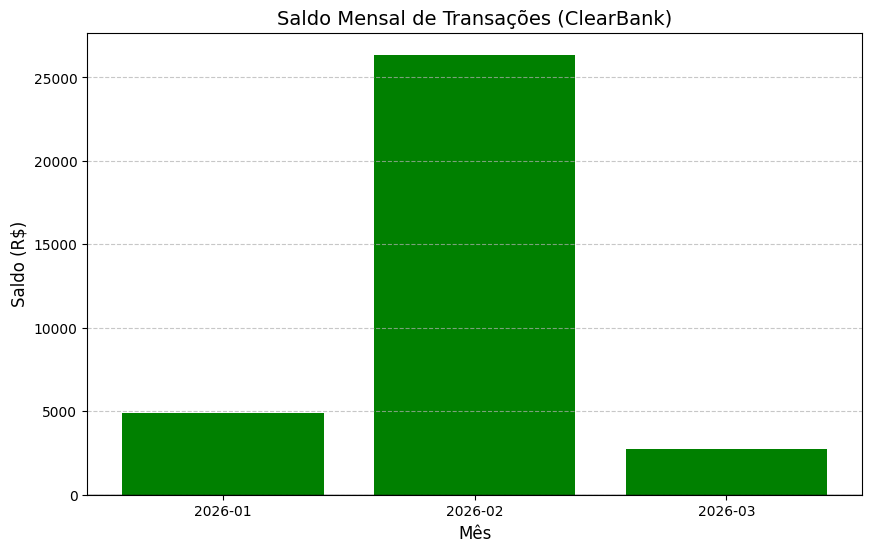

Gráfico 'grafico.png' gerado e salvo com sucesso!


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import json

# Carrega os dados processados do JSON
with open('relatorio.json', 'r', encoding='utf-8') as f:
    dados_relatorio = json.load(f)

# Converte o dicionário 'resumo mensal' para um DataFrame do Pandas
df_mensal = pd.DataFrame.from_dict(dados_relatorio['resumo mensal'], orient='index')

# Opção A: Gráfico de barras com o saldo mensal
plt.figure(figsize=(10, 6))
cores = ['green' if saldo >= 0 else 'red' for saldo in df_mensal['saldo']]

plt.bar(df_mensal.index, df_mensal['saldo'], color=cores)

plt.title('Saldo Mensal de Transações (ClearBank)', fontsize=14)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Saldo (R$)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.axhline(0, color='black', linewidth=1) # Linha do zero

# Salva o gráfico como exigido nos requisitos opcionais
plt.savefig('grafico.png', bbox_inches='tight')
plt.show()

print("Gráfico 'grafico.png' gerado e salvo com sucesso!")